In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import sys
from pathlib import Path

# Run from repo root. If you're elsewhere, uncomment and set this.
# os.chdir("/path/to/movebench")

# IMPORTANT: movebench uses MOVEBENCH_DATA_ROOT to find studies.
# If unset, it defaults to <repo>/data/movebench.
# os.environ["MOVEBENCH_DATA_ROOT"] = "/absolute/path/to/movebench_data"

repo_root = Path.cwd().resolve()
sys.path.insert(0, str(repo_root))

print("repo_root:", repo_root)
print("MOVEBENCH_DATA_ROOT:", os.environ.get("MOVEBENCH_DATA_ROOT"))


repo_root: /data/vision/beery/scratch/justin/movebench/notebooks
MOVEBENCH_DATA_ROOT: None


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import torch

from movebench import Study

In [4]:
# Study to inspect
study_id = "Batbayar_Demoiselle_crane" #"tsavo_lions"
config_path = "../configs/layers_all.yaml"
split = "train"  # or "test"
idx = 0  # dataset index within the split

study = Study(study_id)
plan = study.layer_plan(config_path)

print("study_dir:", study.study_dir)
print("trajectories_path:", study.trajectories_path)
print("config_hash:", plan.config_hash)
print("rasters_hash:", plan.rasters_hash)
print("rasters_root:", study.study_dir / "rasters" / plan.rasters_hash)
print("layers:", len(plan.layers_in_order))
print("channels:", plan.num_channels())
print("derived:", sorted(plan.derived_dependencies.keys()))


study_dir: /archive/vision/beery/movebench/studies_10ind/Batbayar_Demoiselle_crane
trajectories_path: /archive/vision/beery/movebench/studies_10ind/Batbayar_Demoiselle_crane/trajectories.csv
config_hash: d48ca522da00e99e
rasters_hash: 623da2dd6c228978
rasters_root: /archive/vision/beery/movebench/studies_10ind/Batbayar_Demoiselle_crane/rasters/623da2dd6c228978
layers: 22
channels: 94
derived: ['aspect', 'orographic_uplift_hourly', 'rugosity', 'slope', 'thermal_uplift_hourly']


In [5]:
# Create ChipDataset. This requires that the corresponding rasters have been downloaded.
ds = study.chip_dataset(split=split, 
                        config=config_path,
                        mode="steps")
print("len(ds):", len(ds))

/data/vision/beery/scratch/justin/movebench/movebench/trajectories.py:105: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  valid_step_next = df["valid_step"].shift(-1).fillna(False).astype(bool)
/data/vision/beery/scratch/justin/movebench/movebench/trajectories.py:105: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  valid_step_next = df["valid_step"].shift(-1).fillna(False).astype(bool)


len(ds): 17086


In [6]:
env, valid, y, transform, crs = ds[idx]
band_ids = plan.band_ids_in_order()

print("env:", tuple(env.shape), env.dtype)
print("valid:", tuple(valid.shape), valid.dtype)
print("transform:", transform)
print("crs:", crs)
assert env.shape == valid.shape
assert env.shape[0] == plan.num_channels()

# Invariants: env is materialized to 0.0 where valid=False, and env is finite everywhere.
max_abs_invalid = env[~valid].abs().max().item() if (~valid).any() else 0.0
finite_frac = torch.isfinite(env).float().mean().item()
print("max_abs_invalid:", max_abs_invalid)
print("finite_frac:", finite_frac)


/data/vision/beery/scratch/justin/movebench/movebench/datasets/chips.py:451: UserWarning: At least one chip contained invalid pixels after reprojection onto the fixed deepSSF grid; this can happen when rasters do not fully cover the requested extent. Invalid pixels are treated as zeros.
  warnings.warn(


env: (94, 101, 101) torch.float32
valid: (94, 101, 101) torch.bool
transform: | 501.69, 0.00, 12247784.91|
| 0.00,-501.69, 6182240.00|
| 0.00, 0.00, 1.00|
crs: EPSG:3857
max_abs_invalid: 0.0
finite_frac: 1.0


In [7]:
band_id = "dist_water.dist_water"
bi = band_ids.index(band_id)
x = env[bi]
m = valid[bi]
print("valid_frac:", m.float().mean().item())
print("min/median/max (valid):", x[m].min().item(), x[m].median().item(), x[m].max().item())
print("frac == 30000:", (x[m] == 30000).float().mean().item())


valid_frac: 1.0
min/median/max (valid): -0.577130138874054 0.5307658910751343 3.2708182334899902
frac == 30000: 0.0


In [8]:
band_to_idx = {b: i for i, b in enumerate(band_ids)}
print("example band ids:")
for b in band_ids[:20]:
    print(" ", b)


example band ids:
  modis_lst.LST_Day_1km
  modis_lst.LST_Night_1km
  modis_vi.NDVI
  modis_vi.EVI
  modis_ndsi.NDSI
  modis_bai.BAI
  era5_land_hourly.temperature_2m
  era5_land_hourly.dewpoint_temperature_2m
  era5_land_hourly.total_precipitation
  era5_land_hourly.surface_pressure
  era5_land_hourly.u_component_of_wind_10m
  era5_land_hourly.v_component_of_wind_10m
  era5_land_hourly.surface_solar_radiation_downwards
  era5_land_hourly.surface_thermal_radiation_downwards
  era5_land_hourly.surface_net_solar_radiation
  era5_land_hourly.surface_net_thermal_radiation
  era5_land_hourly.surface_latent_heat_flux
  era5_land_hourly.surface_sensible_heat_flux
  era5_land_hourly.snow_depth
  era5_hourly.boundary_layer_height


In [9]:
def _robust_vmin_vmax(x: np.ndarray, p_lo=2, p_hi=98):
    x = x[np.isfinite(x)]
    if x.size == 0:
        return 0.0, 1.0
    return np.nanpercentile(x, [p_lo, p_hi]).tolist()


def plot_band(band_id: str, *, cmap="viridis"):
    if band_id not in band_to_idx:
        print(f"skip (missing): {band_id}")
        return
    i = band_to_idx[band_id]
    img = env[i].detach().cpu().numpy()
    m = valid[i].detach().cpu().numpy().astype(bool)
    show = np.where(m, img, np.nan)
    vmin, vmax = _robust_vmin_vmax(show)

    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(show, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(f"{band_id} | valid={m.mean():.2f}")
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.show()


def plot_layer(layer: str, *, max_bands=16, ncols=4, cmap="viridis"):
    start, end = plan.layer_slice(layer)
    ids = band_ids[start:end]
    ids = ids[:max_bands]
    ncols = min(ncols, len(ids))
    nrows = int(np.ceil(len(ids) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows), squeeze=False)
    axes = axes.reshape(-1)
    for j, ax in enumerate(axes):
        if j >= len(ids):
            ax.axis("off")
            continue
        bid = ids[j]
        i = band_to_idx[bid]
        img = env[i].detach().cpu().numpy()
        m = valid[i].detach().cpu().numpy().astype(bool)
        show = np.where(m, img, np.nan)
        vmin, vmax = _robust_vmin_vmax(show)
        ax.imshow(show, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(bid)
        ax.axis("off")
    fig.suptitle(layer)
    plt.tight_layout()
    plt.show()


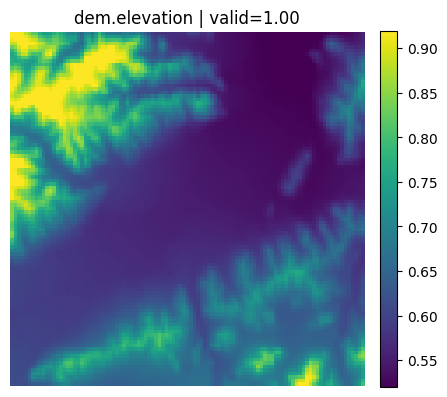

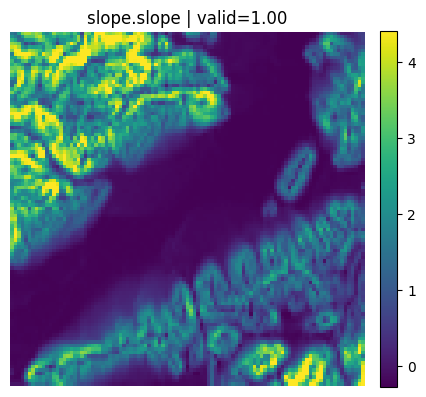

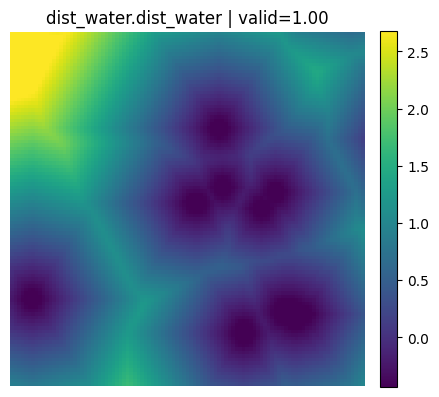

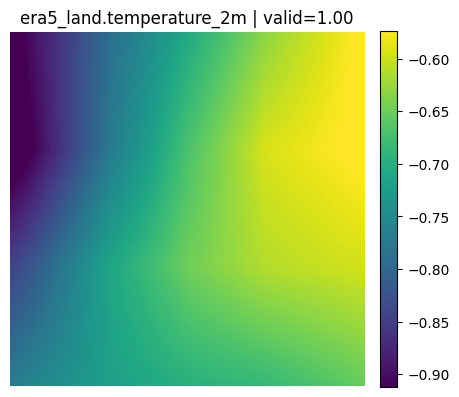

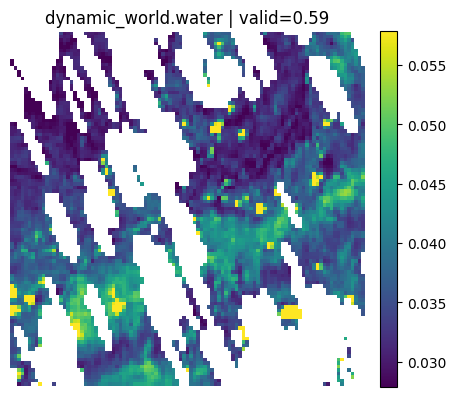

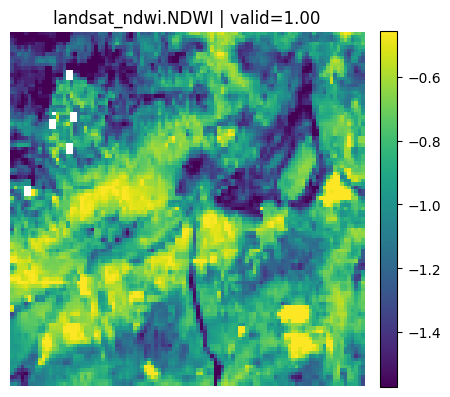

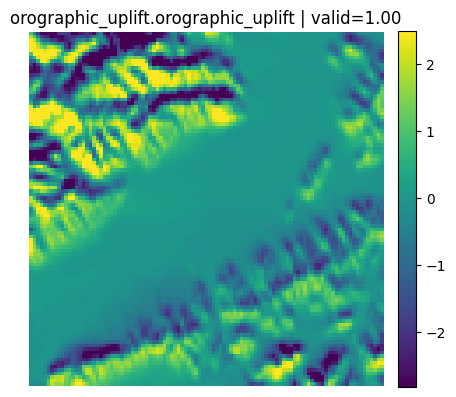

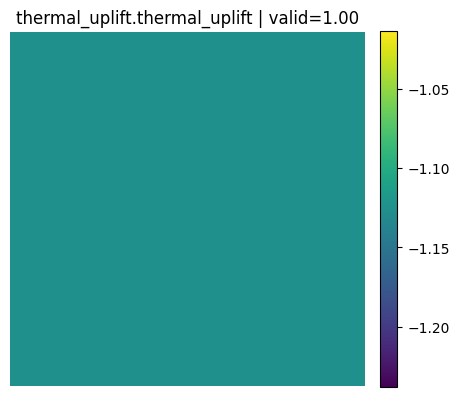

In [10]:
# Plot a few representative bands (skips if not present in this config).
bands_to_plot = [
    "dem.elevation",
    "slope.slope",
    "dist_water.dist_water",
    "era5_land_hourly.temperature_2m",
    "dynamic_world.water",
    "landsat_ndwi.NDWI",
    "orographic_uplift_hourly.orographic_uplift_hourly",
    "thermal_uplift_hourly.thermal_uplift_hourly",
]

for b in bands_to_plot:
    plot_band(b)


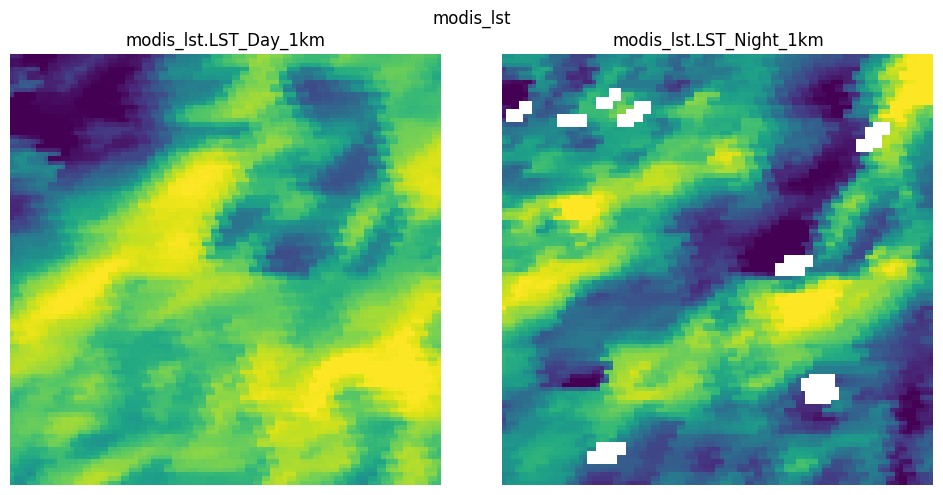

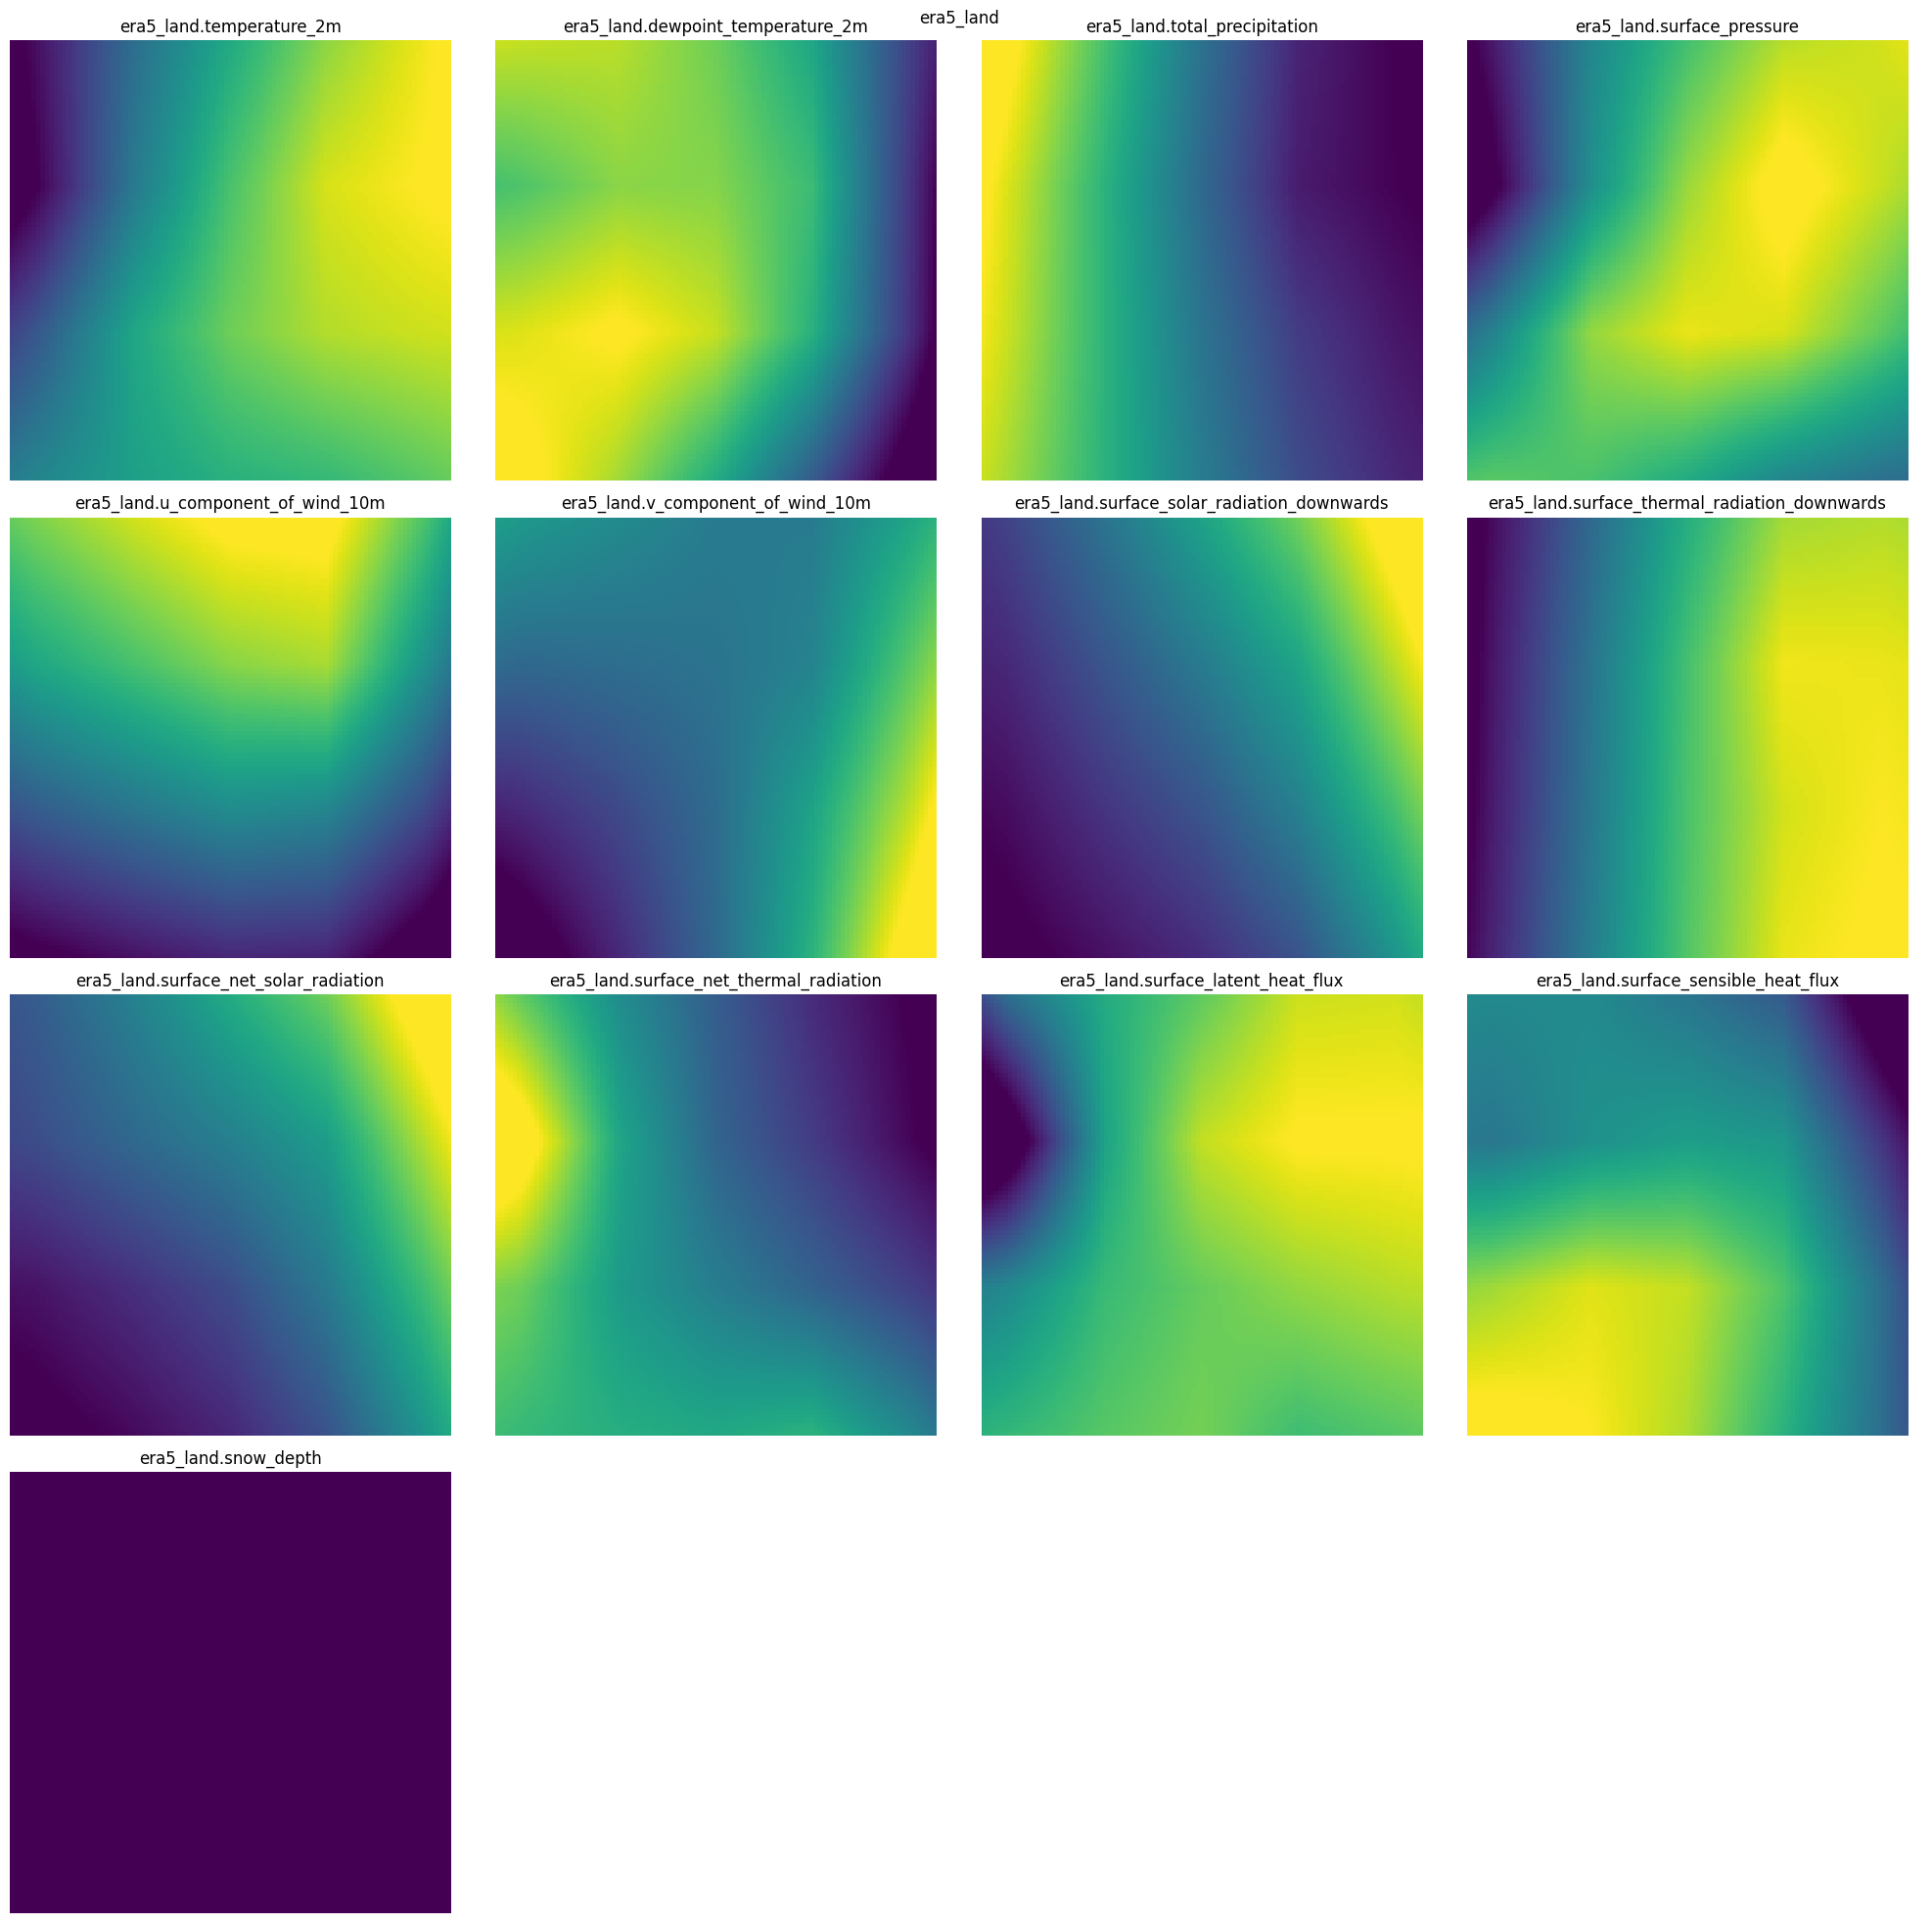

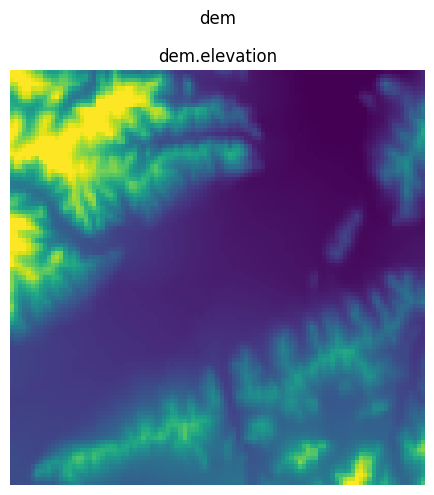

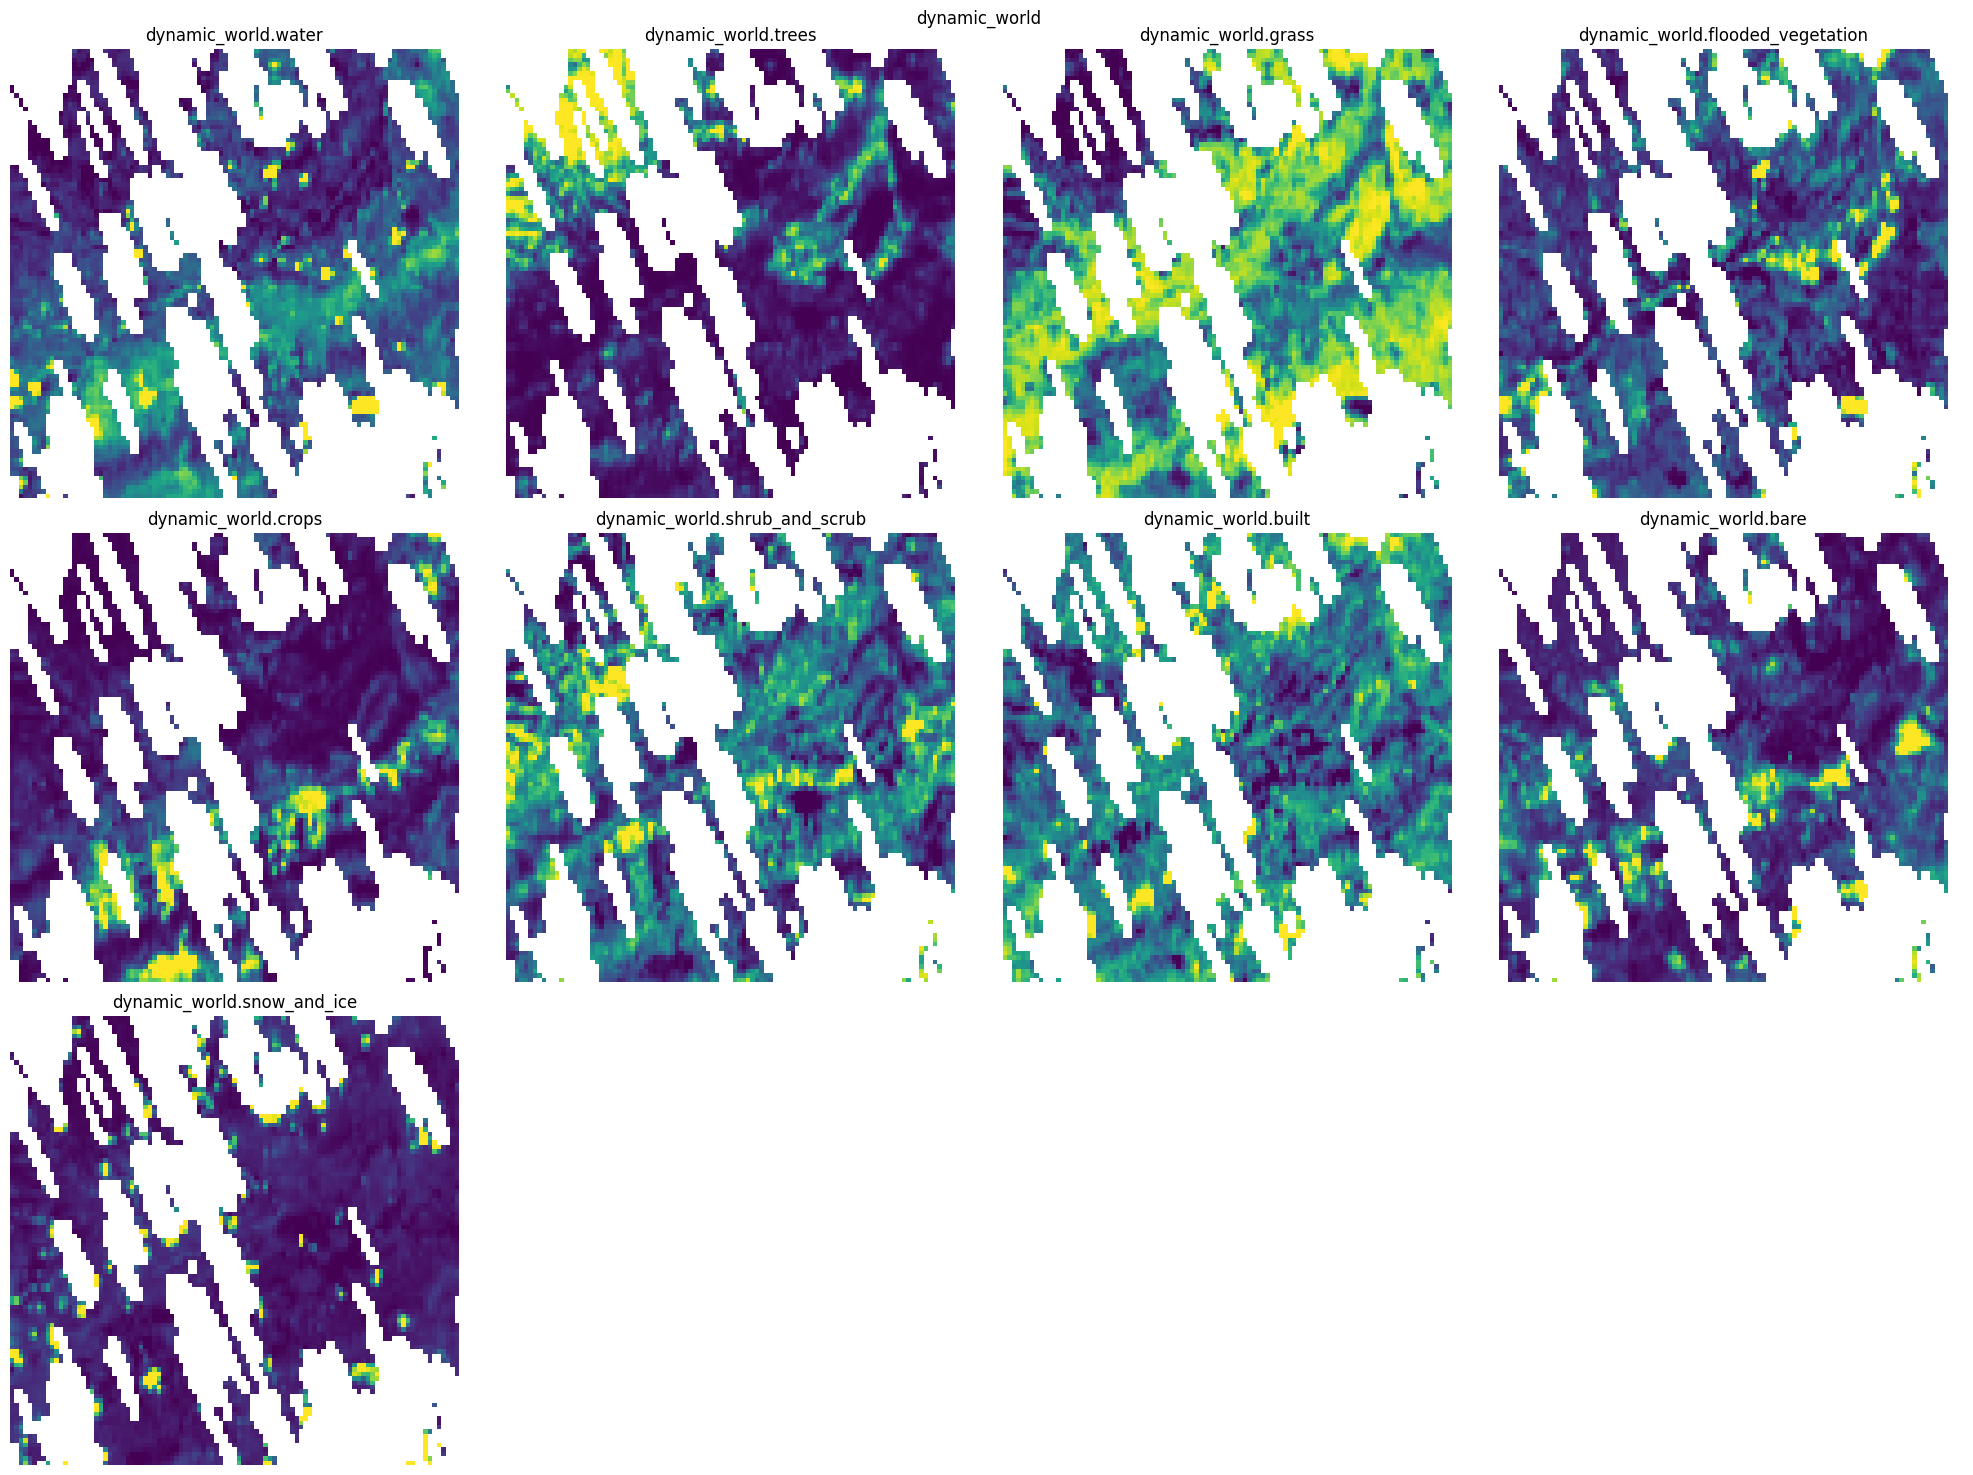

In [11]:
# Plot entire layers (first N bands).
for layer in ["modis_lst", "era5_land_hourly", "dem", "dynamic_world"]:
    if layer in plan.layers_in_order:
        plot_layer(layer)


In [12]:
# If modis_lc is present: check one-hot property.
if "modis_lc" in plan.layers_in_order:
    s, e = plan.layer_slice("modis_lc")
    lc_env = env[s:e]
    lc_valid = valid[s:e]
    lc_any_valid = lc_valid.any(dim=0)
    lc_sum = lc_env.sum(dim=0)
    max_err_valid = (lc_sum[lc_any_valid] - 1.0).abs().max().item() if lc_any_valid.any() else 0.0
    max_sum_invalid = lc_sum[~lc_any_valid].abs().max().item() if (~lc_any_valid).any() else 0.0
    print("modis_lc max |sum-1| on valid pixels:", max_err_valid)
    print("modis_lc max |sum| on invalid pixels:", max_sum_invalid)


modis_lc max |sum-1| on valid pixels: 0.0
modis_lc max |sum| on invalid pixels: 0.0
